# Can one number describe 1989–1991?

A data-use reviewer wants to publish one sentence:

> **"Across 1989–1991, X% of samples in the Wisconsin breast cancer collection were malignant."**

Should they? Or does the data say something that one number would hide? Your job is to find out, and to show the evidence.

*This is a data-readiness exercise. Building classifiers or predicting diagnosis is out of scope.*

## 1 · Load the data (about 10 seconds)
Works from a clone of the repo or in Colab, and checks every file against its published checksum.

In [1]:
import hashlib, pathlib, urllib.request
import pandas as pd
import matplotlib.pyplot as plt

FILES = {
    "wisconsin_readable.csv":        "dcd20439f0e31d26cb210c016f6f226f550afacc21daeb091e57563c7614bddc",
    "data_dictionary.csv":           "e99ada9da83d5d3b30b1206b153388af6fe988171ed5e97557952a8961df88b9",
    "breast-cancer-wisconsin.data":  "402c585309c399237740f635ef9919dc512cca12cbeb20de5e563a4593f22b64",
    "breast-cancer-wisconsin.names": "4bcd6e4e0e4f8ae54e313ebbf18013cc83b6827a207123707687f8f19d29dd2c",
}
RAW = "https://raw.githubusercontent.com/disleveK/oncosys-hackathon-challenge/main/warmup/wisconsin/data/"
DATA = next((d for d in [pathlib.Path("data"), pathlib.Path("../data")] if (d / "wisconsin_readable.csv").exists()), None)
if DATA is None:                                    # e.g. Colab
    DATA = pathlib.Path("data"); DATA.mkdir(exist_ok=True)
    for name in FILES:
        urllib.request.urlretrieve(RAW + name, DATA / name)
for name, expected in FILES.items():
    assert hashlib.sha256((DATA / name).read_bytes()).hexdigest() == expected, f"{name} doesn't match the frozen version"

df = pd.read_csv(DATA / "wisconsin_readable.csv")
dictionary = pd.read_csv(DATA / "data_dictionary.csv")
print(f"{len(df)} samples, {df.shape[1]} columns. Checksums OK.")
df.head()

699 samples, 15 columns. Checksums OK.


,source_row,sample_code,clump_thickness,uniformity_cell_size,uniformity_cell_shape,marginal_adhesion,single_epithelial_cell_size,bare_nuclei,bland_chromatin,normal_nucleoli,mitoses,class_code,collection_group_derived,collection_period_derived,class_label
0,1,1000025,5,1,1,1,2,1.0,3,1,1,2,1,1989-01,benign
1,2,1002945,5,4,4,5,7,10.0,3,2,1,2,1,1989-01,benign
2,3,1015425,3,1,1,1,2,2.0,3,1,1,2,1,1989-01,benign
3,4,1016277,6,8,8,1,3,4.0,3,7,1,2,1,1989-01,benign
4,5,1017023,4,1,1,3,2,1.0,3,1,1,2,1,1989-01,benign


## 2 · What does one row mean?
Each row is one sample record. Columns marked **DERIVED** were reconstructed by the organizers from UCI's documentation. They aren't in the source data, so treat them as assumptions.

In [2]:
dictionary[["column", "origin", "description"]]

,column,origin,description
0,source_row,added by organizers,Row position in the official UCI file (data/br...
1,sample_code,UCI raw file (field 1),Sample code number. Identifies a sample record...
2,clump_thickness,UCI raw file (field 2),Clump thickness of cells in a fine-needle aspi...
3,uniformity_cell_size,UCI raw file (field 3),Uniformity of cell size. Scored 1-10.
4,uniformity_cell_shape,UCI raw file (field 4),Uniformity of cell shape. Scored 1-10.
5,marginal_adhesion,UCI raw file (field 5),Marginal adhesion. Scored 1-10.
6,single_epithelial_cell_size,UCI raw file (field 6),Single epithelial cell size. Scored 1-10.
7,bare_nuclei,UCI raw file (field 7),Bare nuclei. Scored 1-10. Empty where the offi...
8,bland_chromatin,UCI raw file (field 8),Bland chromatin. Scored 1-10.
9,normal_nucleoli,UCI raw file (field 9),Normal nucleoli. Scored 1-10.


## 3 · A first look: when did the samples arrive?

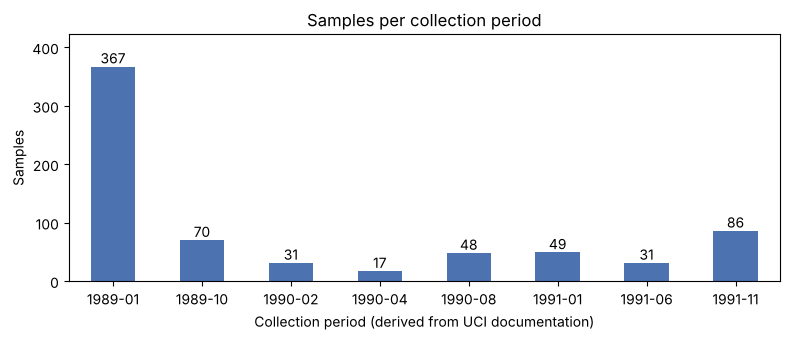

In [3]:
counts = df.groupby("collection_period_derived").size()
ax = counts.plot.bar(color="#4C72B0", figsize=(8, 3.5), rot=0)
ax.set_ylim(0, counts.max() * 1.15)
ax.set_xlabel("Collection period (derived from UCI documentation)")
ax.set_ylabel("Samples")
ax.set_title("Samples per collection period")
for i, n in enumerate(counts):
    ax.annotate(str(n), (i, n), ha="center", va="bottom")
plt.tight_layout(); plt.show()

The groups are very different sizes. **What would that do to a single pooled figure?** That's the start of your investigation.

## 4 · Trace any result to its source
Every row keeps `source_row`, its position in the official UCI file. Use it so a judge can check your work.

In [4]:
df.loc[df["bare_nuclei"].isna(), ["source_row", "sample_code", "collection_group_derived"]].head()

,source_row,sample_code,collection_group_derived
23,24,1057013,1
40,41,1096800,1
139,140,1183246,1
145,146,1184840,1
158,159,1193683,1


## Your turn
Some places to look, not a checklist: how groups differ, missing values, repeated sample codes, what UCI's documentation says (`data/breast-cancer-wisconsin.names`, sections 4, 7 and 8), and how sensitive any headline figure is to your choices.

Then test your tool on the cases in `practice/`, and see the main challenge in [`products/`](../../products/README.md).